# _**K Mean Clustring**_

In [1]:
import pandas as pd 
import seaborn as sns 
import matplotlib.pyplot as plt

df = sns.load_dataset('titanic')
df.head()


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [2]:
# model 
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler # normalize krny ky lie use krty hn 


# import the data in features
X = df[['age','fare']]
X.age.fillna(value = X['age'].mean(), inplace=True)


# scaled the data 
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# perform clustring 
model = KMeans(n_clusters=5)
model.fit(X_scaled)

# assign cluster label to the data 
df['cluster'] = model.labels_

C:\Users\server22\AppData\Local\Temp\ipykernel_15432\1354880158.py:8: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  X.age.fillna(value = X['age'].mean(), inplace=True)
C:\Users\server22\AppData\Local\Temp\ipykernel_15432\1354880158.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X.age.fillna(value = X['age'].mean(), inplace=True)


In [3]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,cluster
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False,0
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False,2
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True,0
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False,2
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True,0


In [4]:
df['cluster'].nunique()

5

In [5]:
df['cluster'].unique()

array([0, 2, 3, 4, 1], dtype=int32)

In [6]:
X.head()

,age,fare
0,22.0,7.2500
1,38.0,71.2833
2,26.0,7.9250
3,35.0,53.1000
4,35.0,8.0500


In [7]:
X_scaled

array([[-0.5924806 , -0.50244517],
       [ 0.63878901,  0.78684529],
       [-0.2846632 , -0.48885426],
       ...,
       [ 0.        , -0.17626324],
       [-0.2846632 , -0.04438104],
       [ 0.17706291, -0.49237783]], shape=(891, 2))

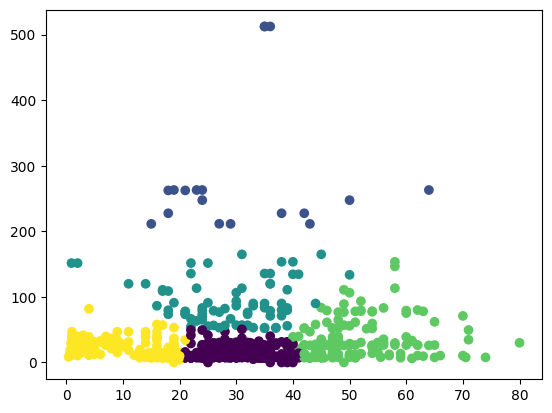

In [8]:
plt.scatter(df['age'], df['fare'], c=df['cluster'])
plt.show()

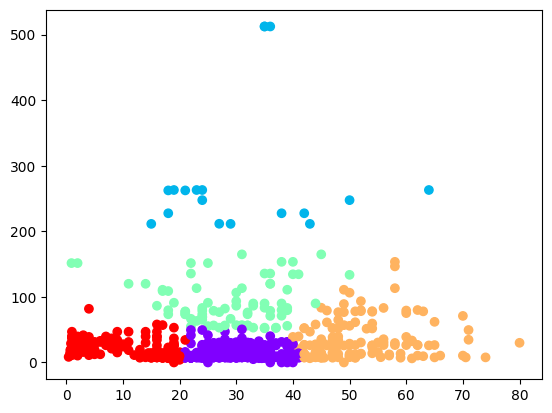

In [9]:
plt.scatter(df['age'], df['fare'], c=df['cluster'], cmap='rainbow')
plt.show()

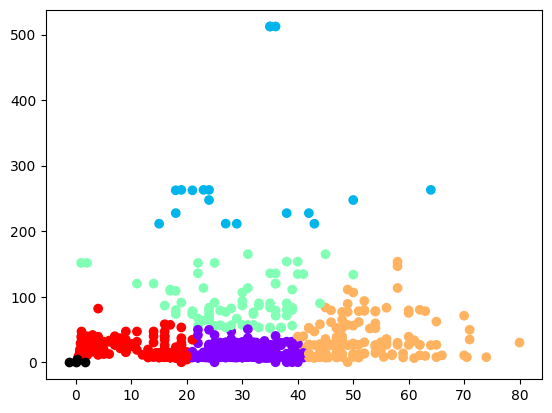

In [10]:
plt.scatter(df['age'], df['fare'], c=df['cluster'], cmap='rainbow')
plt.scatter(model.cluster_centers_[:,0], model.cluster_centers_[:,1], color='black' )
plt.show()

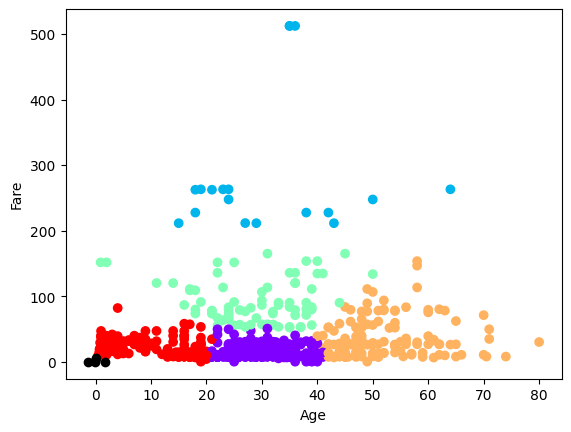

In [11]:
# giving label 
plt.scatter(df['age'], df['fare'], c=df['cluster'], cmap='rainbow')
plt.scatter(model.cluster_centers_[:,0], model.cluster_centers_[:,1], color='black' )
plt.xlabel('Age')
plt.ylabel('Fare')
plt.show()

In [12]:
import plotly.express as px
fig = px.scatter(df, x='age', y='fare' , color='cluster')
fig.show()

In [13]:
import plotly.express as px
fig = px.scatter_3d(df, x='age', y='fare' , z= 'pclass' , color='cluster')
fig.show()

In [14]:
fig = px.parallel_coordinates(df, color='cluster', title='Titanic Clusters')
fig.show()

In [15]:
pip install joblib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [16]:
# saving the model 
import joblib
joblib.dump(model, 'KMeansClustering.joblib')

['KMeansClustering.joblib']

In [17]:
# load the saved model
model_loaded = joblib.load('KMeansClustering.joblib')

In [18]:
import seaborn as sns

df_1 = sns.load_dataset('tips')
df_1

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


In [19]:
X = df_1.drop(columns=['sex'])
y = df_1['sex']

In [20]:
df_1.isnull().sum()

total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64

In [21]:
df_1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB


In [22]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
le.fit(df_1['smoker'])

df_1['smoker'] = le.transform(df_1['smoker'])

In [23]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
#fit the model 
le.fit(df_1['day'])
# transorm the model 
df_1['day'] = le.transform(df_1['day'])


In [24]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
le.fit(df_1['time'])

df_1['time'] = le.transform(df_1['time'])

In [25]:
df_1

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,0,2,0,2
1,10.34,1.66,Male,0,2,0,3
2,21.01,3.50,Male,0,2,0,3
3,23.68,3.31,Male,0,2,0,2
4,24.59,3.61,Female,0,2,0,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,0,1,0,3
240,27.18,2.00,Female,1,1,0,2
241,22.67,2.00,Male,1,1,0,2
242,17.82,1.75,Male,0,1,0,2


In [26]:
X = df_1.drop(columns=['sex'])
y = df_1['sex']

In [27]:
X.head()

,total_bill,tip,smoker,day,time,size
0,16.99,1.01,0,2,0,2
1,10.34,1.66,0,2,0,3
2,21.01,3.50,0,2,0,3
3,23.68,3.31,0,2,0,2
4,24.59,3.61,0,2,0,4


In [28]:
y.head()

0    Female
1      Male
2      Male
3      Male
4    Female
Name: sex, dtype: category
Categories (2, object): ['Male', 'Female']

In [29]:
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier()
model = model.fit(X,y)

In [30]:
joblib.dump(model, "tipswalamodel.joblib")

['tipswalamodel.joblib']

In [31]:
joblib.load("tipswalamodel.joblib")

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [32]:
import pickle
# #save the model 
with open("model.pkl", "wb")as f:  #write binary
    pickle.dump(model, f)

# load the model
with open("model.pkl", 'rb' )as f: # read binary 
    loaded_model = pickle.load(f)